In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [10]:
df =pd.read_csv("cropdata.csv")
df =df.dropna(how='all')
df = df.replace(['', 'N/A','NaN','NC', 'UNKNOWN','ERROR', None], np.nan)
df

,crop ID,soil_type,Seedling Stage,MOI,temp,humidity,result
0,Wheat,Black Soil,Germination,1,25,80.0,1
1,Wheat,Black Soil,Germination,2,26,77.0,1
2,Wheat,Black Soil,Germination,3,27,74.0,1
3,Wheat,Black Soil,Germination,4,28,71.0,1
4,Wheat,Black Soil,Germination,5,29,68.0,1
...,...,...,...,...,...,...,...
16406,Chilli,Chalky Soil,Flowering,75,16,88.0,0
16407,Chilli,Chalky Soil,Flowering,76,15,89.0,0
16408,Chilli,Chalky Soil,Flowering,77,14,90.0,0
16409,Chilli,Chalky Soil,Flowering,78,13,91.0,0


In [12]:
print(df.duplicated().sum())

0


In [11]:
df = df.drop_duplicates().reset_index(drop=True)
df

,crop ID,soil_type,Seedling Stage,MOI,temp,humidity,result
0,Wheat,Black Soil,Germination,1,25,80.0,1
1,Wheat,Black Soil,Germination,2,26,77.0,1
2,Wheat,Black Soil,Germination,3,27,74.0,1
3,Wheat,Black Soil,Germination,4,28,71.0,1
4,Wheat,Black Soil,Germination,5,29,68.0,1
...,...,...,...,...,...,...,...
16278,Chilli,Chalky Soil,Flowering,75,16,88.0,0
16279,Chilli,Chalky Soil,Flowering,76,15,89.0,0
16280,Chilli,Chalky Soil,Flowering,77,14,90.0,0
16281,Chilli,Chalky Soil,Flowering,78,13,91.0,0


In [13]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
crop ID,16283,5,Wheat,6213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
soil_type,16283,7,Clay Soil,3667,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Seedling Stage,16283,8,Flowering,2933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MOI,16283.0,NaN,NaN,NaN,43.781858,27.198158,1.0,21.0,41.0,64.0,100.0
temp,16283.0,NaN,NaN,NaN,28.912547,9.692754,13.0,21.0,29.0,37.0,46.0
humidity,16283.0,NaN,NaN,NaN,63.316004,22.634381,15.0,44.0,69.0,83.0,91.0
result,16283.0,NaN,NaN,NaN,0.520236,0.622436,0.0,0.0,0.0,1.0,2.0


In [14]:
df['result'].value_counts().sort_index()

result
0    8934
1    6227
2    1122
Name: count, dtype: int64

In [ ]:
numeric_cols = ['MOI', 'temp', 'humidity']

print(df[numeric_cols].describe())

                MOI          temp      humidity
count  16283.000000  16283.000000  16283.000000
mean      43.781858     28.912547     63.316004
std       27.198158      9.692754     22.634381
min        1.000000     13.000000     15.000000
25%       21.000000     21.000000     44.000000
50%       41.000000     29.000000     69.000000
75%       64.000000     37.000000     83.000000
max      100.000000     46.000000     91.000000
MOI         0
temp        0
humidity    0
dtype: int64


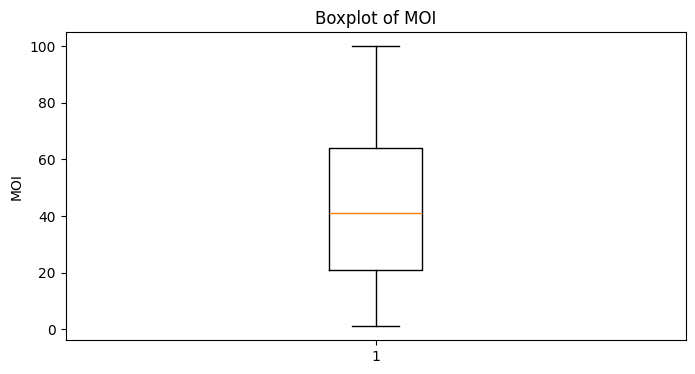

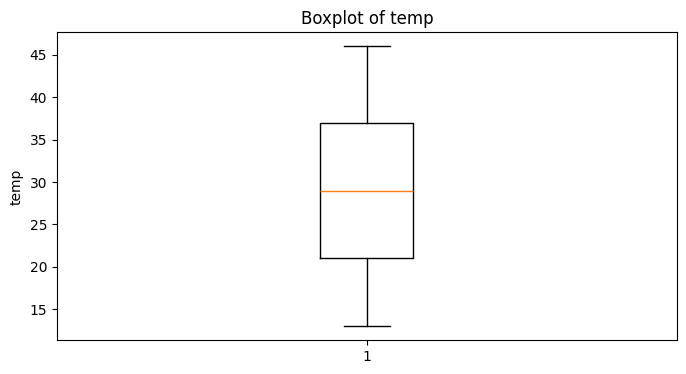

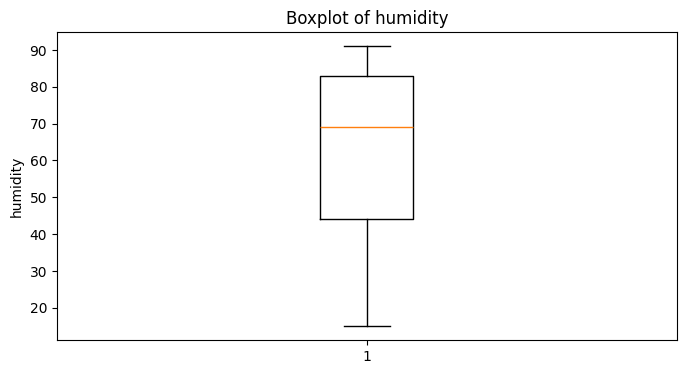

In [ ]:
numeric_cols = ['MOI', 'temp', 'humidity']

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.boxplot(df[col])
    plt.title(f'Boxplot of {col}')
    plt.ylabel(col)
    plt.show()

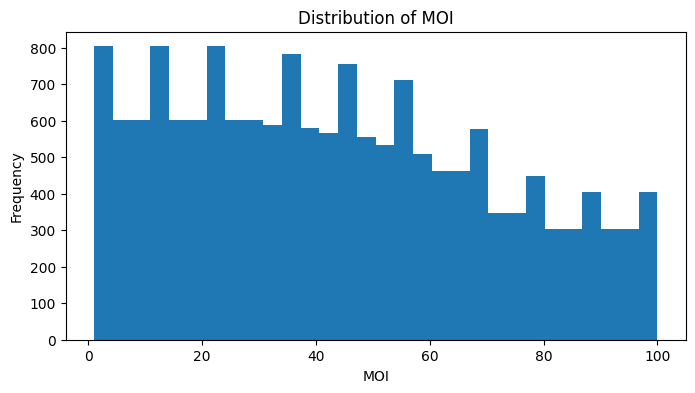

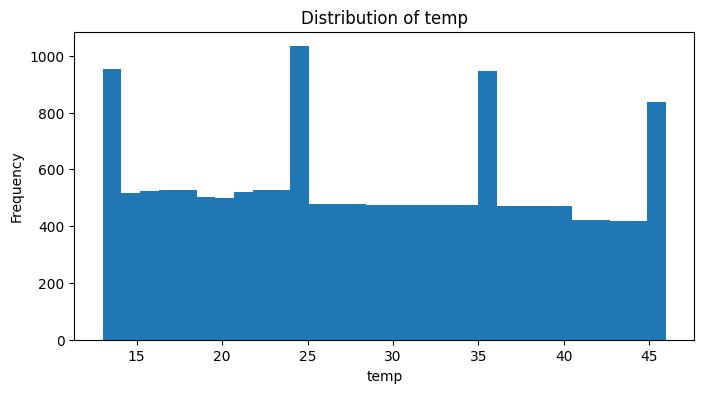

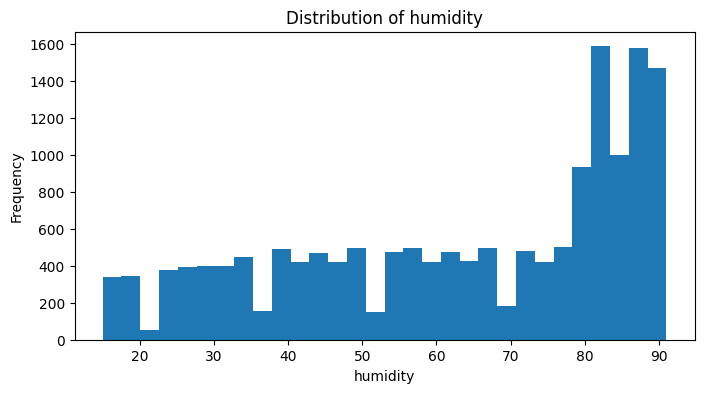

In [18]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    plt.hist(df[col], bins=30)
    plt.title(f'Distribution of {col}')
    plt.xlabel(col)
    plt.ylabel('Frequency')
    plt.show()

In [ ]:
X = df.drop('result', axis=1)
y = df['result']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

X_train: (13026, 6)
X_test : (3257, 6)

y_train:
result
0    7147
1    4981
2     898
Name: count, dtype: int64

y_test:
result
0    1787
1    1246
2     224
Name: count, dtype: int64


In [26]:
numeric_cols = [
    'MOI',
    'temp',
    'humidity'
]

categorical_cols = [
    'crop ID',
    'soil_type',
    'Seedling Stage'
]

In [ ]:
from sklearn.preprocessing import OneHotEncoder
encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=False
)
X_train_encoded = encoder.fit_transform(
    X_train[categorical_cols]
)
X_test_encoded = encoder.transform(
    X_test[categorical_cols]
)
#print("Train encoded shape:", X_train_encoded.shape)
#print("Test encoded shape:", X_test_encoded.shape)
X_train_numeric = X_train[numeric_cols].values
X_test_numeric = X_test[numeric_cols].values
#print("Train numeric shape:", X_train_numeric.shape)
#print("Test numeric shape:", X_test_numeric.shape)
X_train_final = np.hstack([
    X_train_numeric,
    X_train_encoded
])

X_test_final = np.hstack([
    X_test_numeric,
    X_test_encoded
])
#print("X_train_final shape:", X_train_final.shape)
#print("X_test_final shape:", X_test_final.shape)

X_train_final shape: (13026, 23)
X_test_final shape: (3257, 23)


In [31]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=-1
)
model.fit(
    X_train_final,
    y_train
)

RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=42)

In [32]:
y_pred = model.predict(X_test_final)
print("Predictions:")
print(y_pred[:20])

print("\nActual:")
print(y_test.values[:20])

Predictions:
[1 1 0 0 0 0 1 0 0 0 0 0 0 1 1 1 0 0 2 0]

Actual:
[1 1 0 0 0 0 1 0 0 0 0 0 0 1 1 1 0 0 2 0]


In [33]:
from sklearn.metrics import accuracy_score
accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)

Accuracy: 0.9914031317163033


In [34]:
new_data = pd.DataFrame({
    'crop ID': ['Wheat'],
    'soil_type': ['Clay Soil'],
    'Seedling Stage': ['Flowering'],
    'MOI': [20],
    'temp': [35],
    'humidity': [50]
})
new_encoded = encoder.transform(
    new_data[categorical_cols]
)

new_numeric = new_data[numeric_cols].values
new_final = np.hstack([
    new_numeric,
    new_encoded
])
prediction = model.predict(new_final)

print("Prediction:", prediction[0])

Prediction: 1
